# Activity: Perform multiple linear regression


## Introduction



* Exploring and cleaning data
* Using plots and descriptive statistics to select the independent variables
* Creating a fitting multiple linear regression model
* Checking model assumptions
* Interpreting model outputs and communicating the results to non-technical stakeholders

## Step 1: Imports

### Import packages

Import relevant Python libraries and modules.

In [1]:
# Import libraries and modules.

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols

### Load dataset

`Pandas` was used to load the dataset `marketing_sales_data.csv` as `data`, now display the first five rows. The variables in the dataset have been adjusted to suit the objectives of this lab. As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
# RUN THIS CELL TO IMPORT YOUR DATA.

data = pd.read_csv('marketing_sales_data.csv')

# Display the first five rows.

data.head(5)

,TV,Radio,Social Media,Influencer,Sales
0,Low,1.218354,1.270444,Micro,90.054222
1,Medium,14.949791,0.274451,Macro,222.741668
2,Low,10.377258,0.061984,Mega,102.774790
3,High,26.469274,7.070945,Micro,328.239378
4,High,36.876302,7.618605,Mega,351.807328


## Step 2: Data exploration

### Familiarize yourself with the data's features

Start with an exploratory data analysis to familiarize yourself with the data and prepare it for modeling.

The features in the data are:

* TV promotional budget (in "Low," "Medium," and "High" categories)
* Social media promotional budget (in millions of dollars)
* Radio promotional budget (in millions of dollars)
* Sales (in millions of dollars)
* Influencer size (in "Mega," "Macro," "Micro," and "Nano" categories)


**Question:** What are some purposes of EDA before constructing a multiple linear regression model?

* Understanding which variables are present in the data
* Reviewing the distribution of features, such as minimum, mean, and maximum values
* Plotting the relationship between the independent and dependent variables to visualize which features have a linear relationship
* Identifying issues with the data, such as incorrect values (e.g., typos) or missing values

### Remove missing data

This dataset contains rows with missing values. To correct this, drop all rows that contain missing data.

In [3]:
# Drop rows that contain missing data and update the DataFrame.

n_before = len(data)
print(data.isna().sum())
data = data.dropna(axis=0).reset_index(drop=True)
print(f"\nDropped {n_before - len(data)} rows with missing values -> {len(data)} rows remain")
print(f"Duplicate rows: {data.duplicated().sum()}")

TV              1
Radio           1
Social Media    0
Influencer      0
Sales           1
dtype: int64

Dropped 3 rows with missing values -> 569 rows remain
Duplicate rows: 0


### Clean column names

The `ols()` function doesn't run when variable names contain a space. Check that the column names in `data` do not contain spaces and fix them, if needed.

In [4]:
# Rename all columns in data that contain a space. 

data = data.rename(columns={'Social Media':'Social_Media'})
data.head(10)

,TV,Radio,Social_Media,Influencer,Sales
0,Low,1.218354,1.270444,Micro,90.054222
1,Medium,14.949791,0.274451,Macro,222.741668
2,Low,10.377258,0.061984,Mega,102.774790
3,High,26.469274,7.070945,Micro,328.239378
4,High,36.876302,7.618605,Mega,351.807328
5,High,25.561910,5.459718,Micro,261.966812
6,High,37.263819,6.886535,Nano,349.861575
7,Low,13.187256,2.766352,Macro,140.415286
8,High,29.520170,2.333157,Nano,264.592233
9,Low,3.773287,0.135074,Nano,55.674214


### Train/test split (before any feature selection)

To avoid **selection leakage**, the hold-out test set is separated *before* exploring relationships or choosing variables. All EDA, feature selection, and assumption checks below use the training set only; the test set is touched once, in Step 5, to estimate out-of-sample performance.

In [5]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(data, test_size=0.20, random_state=42)
print(f"Train: {train_df.shape}, Test: {test_df.shape}")

Train: (455, 5), Test: (114, 5)


### Create a pairplot of the data

Create a pairplot to visualize the relationship between the continous variables in the **training** data.

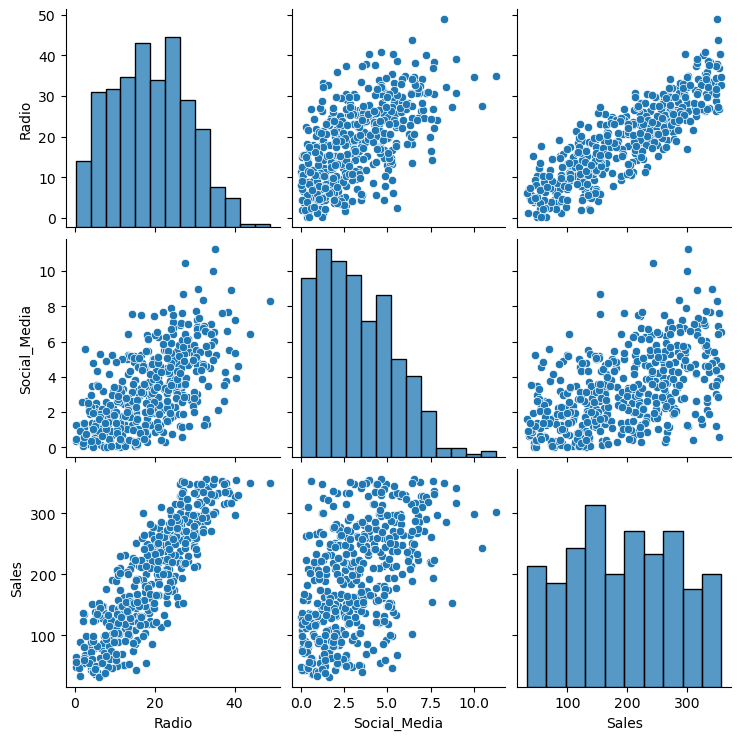

In [6]:
# Create a pairplot of the training data.

sns.pairplot(train_df)

Radio and Social Media both appear to have linear relationships with Sales in the training data. Given this, Radio and Social Media may be useful as independent variables in a multiple linear regression model estimating Sales.

TV and Influencer are excluded from the pairplot because they are not numeric.

### Calculate the mean sales for each categorical variable

There are two categorical variables: `TV` and `Influencer`. To characterize the relationship between the categorical variables and `Sales`, find the mean `Sales` for each category in `TV` and the mean `Sales` for each category in `Influencer`. 

In [7]:
# Calculate the mean sales for each TV category (training data). 

print(train_df.groupby('TV')['Sales'].mean())
print('')


# Calculate the mean sales for each Influencer category (training data). 

print(train_df.groupby('Influencer')['Sales'].mean())

TV
High      299.672600
Low        92.483862
Medium    197.622377
Name: Sales, dtype: float64

Influencer
Macro    205.456306
Mega     176.812767
Micro    199.606065
Nano     191.184491
Name: Sales, dtype: float64


Mean sales differ sharply across TV budget levels (High ≫ Medium ≫ Low), so TV is a strong candidate predictor. Mean sales across Influencer tiers are much closer together, suggesting Influencer has little explanatory power.

## Step 3: Model building

### Fit a multiple linear regression model that predicts sales

Compare candidate formulas **on the training data only**, then fit the chosen model.

In [8]:
# Compare candidate models on the training data only
candidates = [
    'Sales ~ C(TV)',
    'Sales ~ C(TV) + Radio',
    'Sales ~ C(TV) + Radio + Social_Media',
    'Sales ~ C(TV) + Radio + Social_Media + C(Influencer)',
]
cand_rows = []
for f in candidates:
    m = ols(formula=f, data=train_df).fit()
    cand_rows.append({'Formula': f, 'Adj R²': m.rsquared_adj, 'AIC': m.aic, 'BIC': m.bic})
print(pd.DataFrame(cand_rows).round(4).to_string(index=False))

                                             Formula  Adj R²       AIC       BIC
                                       Sales ~ C(TV)  0.8647 4463.3476 4475.7085
                               Sales ~ C(TV) + Radio  0.9002 4326.0813 4342.5625
                Sales ~ C(TV) + Radio + Social_Media  0.9002 4326.9885 4347.5900
Sales ~ C(TV) + Radio + Social_Media + C(Influencer)  0.8997 4332.0108 4364.9732


In [9]:
# Define the OLS formula.

ols_formula = 'Sales ~ C(TV) + Radio'

# Create an OLS model on the TRAINING data.

OLS = ols(formula=ols_formula, data=train_df)

# Fit the model.

model = OLS.fit()

# Save the results summary.

model_results = model.summary()

# Display the model results.

print(model_results)

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.900
Method:                 Least Squares   F-statistic:                     1366.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):          7.78e-226
Time:                        00:59:45   Log-Likelihood:                -2159.0
No. Observations:                 455   AIC:                             4326.
Df Residuals:                     451   BIC:                             4343.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         212.5572      7.265     

**Variable selection (decided on the training data only):**

* **TV** was selected: mean Sales differ sharply between TV levels, and `C(TV)` alone already explains ~86% of the variance.
* **Radio** was selected: it shows a strong linear relationship with Sales, and adding it raises adjusted R² from 0.865 to 0.900 and lowers AIC by ~137.
* **Social Media** was not selected: adding it leaves adjusted R² unchanged (0.9002) and worsens AIC/BIC. It is correlated with Radio, so it carries little extra information.
* **Influencer** was not selected: adding it lowers adjusted R² and worsens AIC/BIC.

### Check model assumptions

For multiple linear regression, there is an additional assumption added to the four simple linear regression assumptions: **multicollinearity**. 

Check that all five multiple linear regression assumptions are upheld for your model.

### Model assumption: Linearity

Create scatterplots comparing the continuous independent variable(s) you selected previously with `Sales` to check the linearity assumption. Use the pairplot you created earlier to verify the linearity assumption or create new scatterplots comparing the variables of interest.

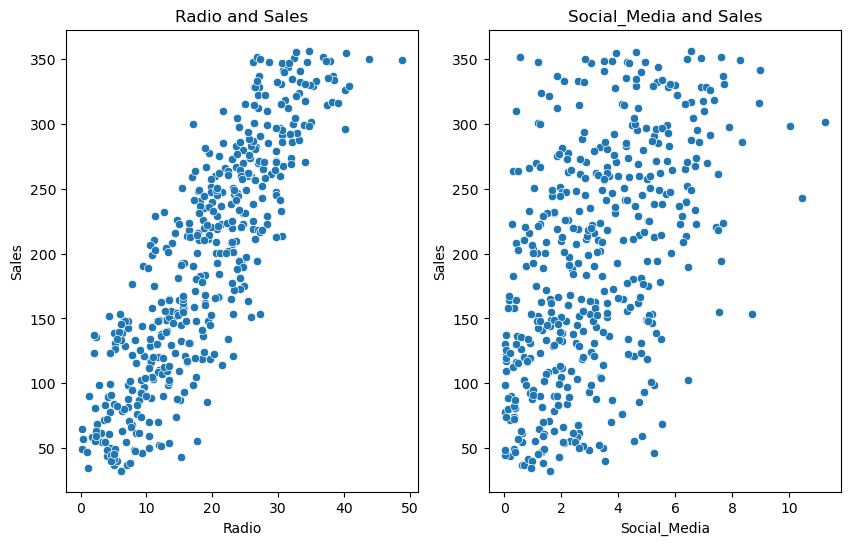

In [10]:
# Create a scatterplot for each independent variable and the dependent variable.

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

sns.scatterplot(x=train_df['Radio'], y=train_df['Sales'], ax=axes[0])
axes[0].set_title("Radio and Sales")

sns.scatterplot(x=train_df['Social_Media'] , y=train_df['Sales'], ax=axes[1])
axes[1].set_title('Social_Media and Sales');

The linearity assumption holds for Radio, as there is a clear linear relationship in the scatterplot between Radio and Sales. Social Media was not included in the preceding multiple linear regression model, but it does appear to have a linear relationship with Sales.

### Model assumption: Independence

The **independent observation assumption** states that each observation in the dataset is independent. As each marketing promotion (i.e., row) is independent from one another, the independence assumption is not violated.

### Model assumption: Normality

Create the following plots to check the **normality assumption**:

* **Plot 1**: Histogram of the residuals
* **Plot 2**: Q-Q plot of the residuals

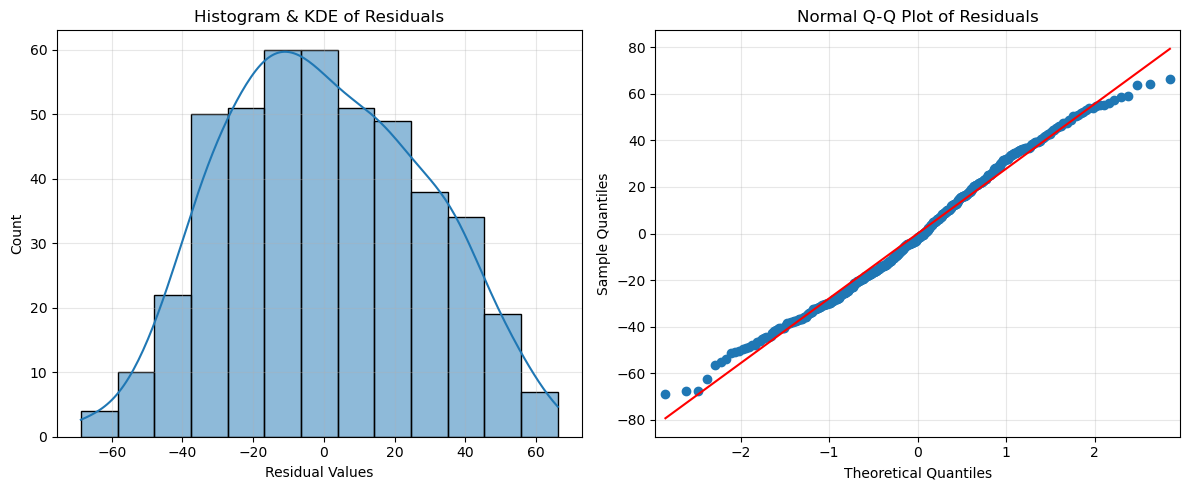

--- FORMAL NORMALITY TESTS ---
Shapiro-Wilk Test : W = 0.9889, p-value = 0.001545
Jarque-Bera Test  : JB = 9.4342, p-value = 0.008941
Omnibus Test      : Stat = 20.1547, p-value = 0.000042


In [11]:
# Calculate the residuals.
residuals = model.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Create a histogram with the residuals
sns.histplot(residuals, kde=True, ax=axes[0], color='#1f77b4') 
axes[0].set_xlabel('Residual Values')
axes[0].set_title('Histogram & KDE of Residuals')
axes[0].grid(True, alpha=0.3)

# Create a Q-Q plot of the residuals
sm.qqplot(residuals, ax=axes[1], line='s')
axes[1].set_title("Normal Q-Q Plot of Residuals")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Formal Normality Tests
from scipy import stats
sw_stat, sw_p = stats.shapiro(residuals[:5000])
jb_stat, jb_p = stats.jarque_bera(residuals)
omnibus_stat, omnibus_p = stats.normaltest(residuals)

print("--- FORMAL NORMALITY TESTS ---")
print(f"Shapiro-Wilk Test : W = {sw_stat:.4f}, p-value = {sw_p:.6f}")
print(f"Jarque-Bera Test  : JB = {jb_stat:.4f}, p-value = {jb_p:.6f}")
print(f"Omnibus Test      : Stat = {omnibus_stat:.4f}, p-value = {omnibus_p:.6f}")


The histogram is roughly bell-shaped and the Q-Q plot is close to the reference line, but the **formal tests reject exact normality** (Shapiro-Wilk p = 0.0015, Jarque-Bera p = 0.009, Omnibus p < 0.001). The residuals are slightly light-tailed (kurtosis ≈ 2.3 < 3), not skewed (skew ≈ 0.1).

**Conclusion:** normality is *mildly* violated. With n = 455 training observations, the Central Limit Theorem makes coefficient tests and confidence intervals robust to this kind of deviation, so the inference remains reliable. Prediction intervals should be read as approximate.

### Model assumption: Constant variance

Check that the **constant variance assumption** is not violated by creating a scatterplot with the fitted values and residuals. Add a line at $y = 0$ to visualize the variance of residuals above and below $y = 0$.

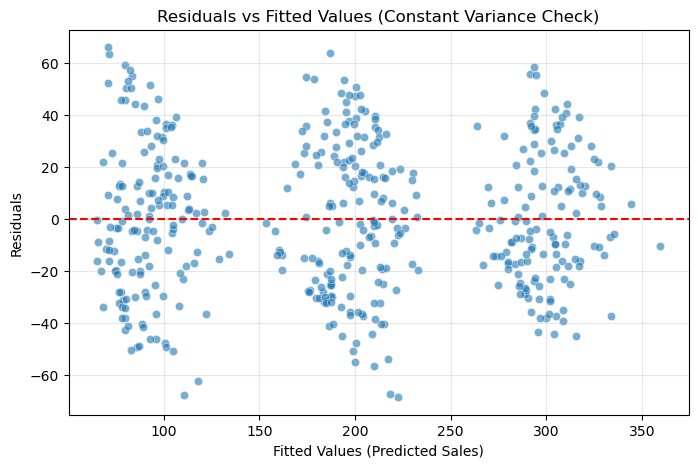

--- FORMAL DIAGNOSTIC TESTS ---
Breusch-Pagan LM Stat : 6.3727, p-value : 0.094819
Durbin-Watson Stat    : 1.8704 (approx 2.0 indicates no autocorrelation)

--- HC3 HETEROSCEDASTICITY-ROBUST RESULTS ---
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.900
Method:                 Least Squares   F-statistic:                     1428.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):          8.40e-230
Time:                        00:59:46   Log-Likelihood:                -2159.0
No. Observations:                 455   AIC:                             4326.
Df Residuals:                     451   BIC:                             4343.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
       

In [12]:
# Scatterplot of fitted values vs residuals
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(x=model.fittedvalues, y=model.resid, alpha=0.6, color='#1f77b4', ax=ax)
ax.set_xlabel('Fitted Values (Predicted Sales)')
ax.set_ylabel('Residuals')
ax.axhline(0, color='red', linestyle='--', linewidth=1.5)
ax.set_title('Residuals vs Fitted Values (Constant Variance Check)')
ax.grid(True, alpha=0.3)
plt.show()

# Formal Breusch-Pagan test for Homoscedasticity
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

bp_lm, bp_p, bp_f, bp_f_p = het_breuschpagan(residuals, model.model.exog)
dw_stat = durbin_watson(residuals)

print("--- FORMAL DIAGNOSTIC TESTS ---")
print(f"Breusch-Pagan LM Stat : {bp_lm:.4f}, p-value : {bp_p:.6f}")
print(f"Durbin-Watson Stat    : {dw_stat:.4f} (approx 2.0 indicates no autocorrelation)")

# Fit HC3 Heteroscedasticity-Robust Standard Errors
print("\n--- HC3 HETEROSCEDASTICITY-ROBUST RESULTS ---")
robust_model = model.get_robustcov_results(cov_type='HC3')
print(robust_model.summary())


The fitted values fall into three groups because the categorical TV variable dominates the model, so TV is the biggest factor deciding sales.

The spread of residuals looks similar across the groups. On the training data the Breusch-Pagan test does not reject constant variance at the 5% level (p = 0.095), but it is borderline (on the full dataset p = 0.018). To be safe, **HC3 heteroscedasticity-robust standard errors** are used for all final inference. They give the same conclusions (all coefficients remain highly significant).

### Model assumption: No multicollinearity

The **no multicollinearity assumption** states that no two independent variables ($X_i$ and $X_j$) can be highly correlated with each other. 

Two common ways to check for multicollinearity are to:

* Create scatterplots to show the relationship between pairs of independent variables
* Use the variance inflation factor to detect multicollinearity

Use one of these two methods to check your model's no multicollinearity assumption.

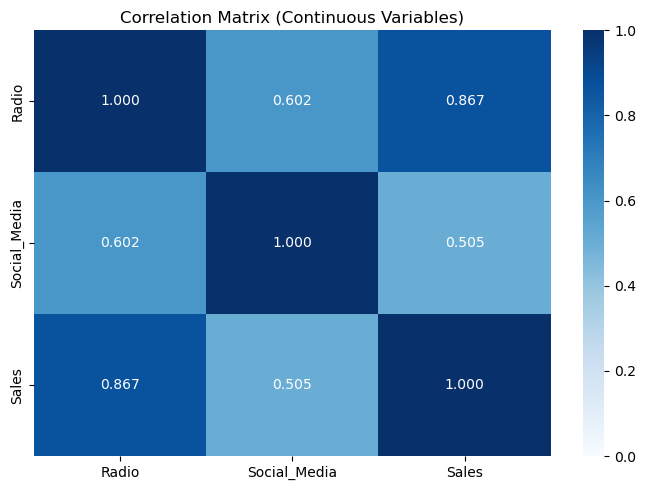

In [13]:
# Correlation Heatmap among candidate predictors
plt.figure(figsize=(7, 5))
corr = train_df[['Radio', 'Social_Media', 'Sales']].corr()
sns.heatmap(corr, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1)
plt.title('Correlation Matrix (Continuous Variables)')
plt.tight_layout()
plt.show()


In [14]:
# Multicollinearity Check: Variance Inflation Factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Continuous candidate predictors (with intercept)
X_cont = add_constant(train_df[['Radio', 'Social_Media']])
vif_cont = pd.DataFrame({
    'Variable': X_cont.columns,
    'VIF': [variance_inflation_factor(X_cont.values, i) for i in range(X_cont.shape[1])]
})
print("--- VIF for Continuous Predictors (with Intercept) ---")
print(vif_cont[vif_cont['Variable'] != 'const'].to_string(index=False))

# 2. Actual Model Design Matrix (TV Dummies + Radio)
X_model = pd.get_dummies(train_df[['TV', 'Radio']], columns=['TV'], drop_first=True).astype(float)
X_model_const = add_constant(X_model)
vif_model = pd.DataFrame({
    'Variable': X_model_const.columns,
    'VIF': [variance_inflation_factor(X_model_const.values, i) for i in range(X_model_const.shape[1])]
})
print("\n--- VIF for Final Model Design Matrix (C(TV) + Radio) ---")
print(vif_model[vif_model['Variable'] != 'const'].to_string(index=False))
print("\nAll VIF values are < 5.0, confirming the No Multicollinearity assumption is satisfied.")


--- VIF for Continuous Predictors (with Intercept) ---
    Variable      VIF
       Radio 1.567954
Social_Media 1.567954

--- VIF for Final Model Design Matrix (C(TV) + Radio) ---
 Variable      VIF
    Radio 2.980328
   TV_Low 4.217322
TV_Medium 2.171532

All VIF values are < 5.0, confirming the No Multicollinearity assumption is satisfied.


### TV and Radio budgets are confounded

VIF is below 5, but a crosstab shows that TV level and Radio spend move together: campaigns with a High TV budget almost always also have high Radio spend. This means the Radio coefficient is estimated mostly *within* each TV tier, and predictions for unusual combinations (e.g. Low TV with very high Radio) are extrapolations.

In [15]:
radio_bins = pd.cut(train_df['Radio'], bins=[0, 10, 20, 30, 50])
print(pd.crosstab(train_df['TV'], radio_bins).reindex(['Low', 'Medium', 'High']))
print()
print(train_df.groupby('TV')['Radio'].agg(['min', 'mean', 'max']).reindex(['Low', 'Medium', 'High']).round(2))

Radio   (0, 10]  (10, 20]  (20, 30]  (30, 50]
TV                                           
Low          87        61         4         0
Medium        9        86        70         3
High          0         8        70        57

          min   mean    max
TV                         
Low      0.19   9.30  23.18
Medium   4.25  18.97  30.68
High    16.85  28.94  48.87


## Step 4: Results and evaluation

### Display the OLS regression results

If the model assumptions are met, you can interpret the model results accurately.

First, display the OLS regression results of the model fitted on the training data.

In [16]:
# Display the model results summary.

model_results

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.900
Method:                 Least Squares   F-statistic:                     1366.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):          7.78e-226
Time:                        00:59:45   Log-Likelihood:                -2159.0
No. Observations:                 455   AIC:                             4326.
Df Residuals:                     451   BIC:                             4343.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         212.5572      7.265     29.258      0.000     198.280     226.835
C(TV)[T.Low]     -148.0843      5.706    -25.951      0.000    -159.298    -136.870
C(TV)[T.Medium]   -72.0469      4.002    -18.003      0.000     -79.911     -64.182
Radio               3.0104      0.237     12.708      0.000       2.545       3.476
==============================================================================
Omnibus:                       20.155   Durbin-Watson:                   1.870
Prob(Omnibus):                  0.000   Jarque-Bera (JB):                9.434
Skew:                           0.105   Prob(JB):                      0.00894
Kurtosis:                       2.326   Cond. No.                         154.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**R² = 0.901 (Adj. R² = 0.900) on the training data:** the model explains about 90% of the variation in Sales. The hold-out test set (Step 5) confirms this generalizes (Test R² = 0.915).

### Interpret model coefficients

With the model fit evaluated, you can look at the coefficient estimates and the uncertainty of these estimates.

For final inference, the selected formula is refit on **all** cleaned data (more data → tighter estimates) with HC3 heteroscedasticity-robust standard errors.

In [17]:
# Final model: selected formula refit on all data with HC3 robust standard errors
final_model = ols(formula=ols_formula, data=data).fit()
final_robust = final_model.get_robustcov_results(cov_type='HC3')

robust_ci = final_robust.conf_int()
coef_summary = pd.DataFrame({
    'Coefficient (Beta)': final_model.params,
    'HC3 Robust SE': final_robust.bse,
    't-statistic': final_robust.tvalues,
    'p-value': final_robust.pvalues,
    '95% CI Lower': robust_ci[:, 0],
    '95% CI Upper': robust_ci[:, 1]
})

print("="*80)
print(f"PARAMETER ESTIMATES WITH HC3 ROBUST INFERENCE (n = {int(final_model.nobs)}, R² = {final_model.rsquared:.4f})")
print("="*80)
print(coef_summary.round(4))

PARAMETER ESTIMATES WITH HC3 ROBUST INFERENCE (n = 569, R² = 0.9044)
                 Coefficient (Beta)  HC3 Robust SE  t-statistic  p-value  \
Intercept                  217.6367         5.6627      38.4336      0.0   
C(TV)[T.Low]              -152.0897         4.4279     -34.3483      0.0   
C(TV)[T.Medium]            -73.4835         3.2992     -22.2730      0.0   
Radio                        2.8864         0.1864      15.4879      0.0   

                 95% CI Lower  95% CI Upper  
Intercept            206.5142      228.7591  
C(TV)[T.Low]        -160.7868     -143.3926  
C(TV)[T.Medium]      -79.9637      -67.0033  
Radio                  2.5203        3.2524  


When the selected model is refit on all 569 observations, the estimated coefficients are:

* $\beta_0 = 217.64$ (Intercept: baseline for **High** TV with zero Radio spend)
* $\beta_{TV\,Low} = -152.09$
* $\beta_{TV\,Medium} = -73.48$
* $\beta_{Radio} = 2.886$


$$\text{Sales} = \beta_0 + \beta_{TV\,Low} \cdot X_{TV\,Low} + \beta_{TV\,Medium} \cdot X_{TV\,Medium} + \beta_{Radio} \cdot X_{Radio}$$

$$\text{Sales} = 217.64 - 152.09 \cdot X_{TV\,Low} - 73.48 \cdot X_{TV\,Medium} + 2.886 \cdot X_{Radio}$$


The reference category for TV is **High** (the omitted category in dummy coding). Both TV coefficients are negative, so sales are significantly lower for Low and Medium TV budgets than for a High TV budget when Radio spend is held constant:

* A Low TV promotional budget yields on average **\$152.09M lower sales** than a High TV promotion.
* A Medium TV promotional budget yields on average **\$73.48M lower sales** than a High TV promotion.
* Each additional **\$1M spent on Radio** is associated with an estimated **+\$2.89M in sales**.

All coefficients are statistically significant (p < 0.001). With HC3 robust standard errors, the 95% confidence intervals are:
* $\beta_{TV\,Low} \in [-160.79, -143.39]$
* $\beta_{TV\,Medium} \in [-79.96, -67.00]$
* $\beta_{Radio} \in [2.52, 3.25]$

**Caution:** TV and Radio budgets are strongly confounded (High-TV campaigns almost always have high Radio spend). These are observational associations, not causal ROI estimates, and predictions for TV/Radio combinations that don't appear in the data are extrapolations.


Beta coefficients allow you to estimate the magnitude and direction (positive or negative) of the effect of each independent variable on the dependent variable. The coefficient estimates can be converted to explainable insights, such as the connection between an increase in TV promotional budgets and sales mentioned previously.

Potential areas to explore include:

Providing the business with the estimated sales given different TV promotions and radio budgets
Additional plots to help convey the results, such as using the seaborn regplot() to plot the data with a best fit regression line

## Step 5: Advanced Business Insights & Predictions

We address the potential exploration areas highlighted in the lab:
1. Forecasting sales across marketing spend scenarios with 95% prediction intervals (flagging extrapolation).
2. Visualizing regression trajectories stratified by TV promotion level (`sns.lmplot`).
3. Quantifying out-of-sample predictive power on the untouched hold-out test set and with 5-fold cross-validation on the training data.


In [18]:
# ============================================================
# Business Scenario Predictions & Actionable Insights
# ============================================================

# Define realistic marketing allocation scenarios
scenarios = pd.DataFrame({
    'Scenario': ['Budget Tier A', 'Budget Tier B', 'Budget Tier C', 'Aggressive Growth'],
    'TV': ['Low', 'Medium', 'High', 'High'],
    'Radio': [5.0, 15.0, 25.0, 35.0]
})

predictions = final_model.predict(scenarios[['TV', 'Radio']])
scenarios['Predicted Sales ($M)'] = predictions.round(2)

# Prediction interval estimates
pred_obj = final_model.get_prediction(scenarios[['TV', 'Radio']])
pred_summary = pred_obj.summary_frame(alpha=0.05)
scenarios['95% PI Lower ($M)'] = pred_summary['obs_ci_lower'].round(2)
scenarios['95% PI Upper ($M)'] = pred_summary['obs_ci_upper'].round(2)

# Flag scenarios whose Radio spend lies outside the range observed for that TV tier
radio_range = data.groupby('TV')['Radio'].agg(['min', 'max'])
scenarios['Within Observed Range'] = [
    radio_range.loc[tv, 'min'] <= r <= radio_range.loc[tv, 'max']
    for tv, r in zip(scenarios['TV'], scenarios['Radio'])
]

print("="*80)
print("MARKETING SCENARIO FORECASTS (WITH 95% PREDICTION INTERVALS)")
print("="*80)
print(scenarios.to_string(index=False))


MARKETING SCENARIO FORECASTS (WITH 95% PREDICTION INTERVALS)
         Scenario     TV  Radio  Predicted Sales ($M)  95% PI Lower ($M)  95% PI Upper ($M)  Within Observed Range
    Budget Tier A    Low    5.0                 79.98              24.82             135.14                   True
    Budget Tier B Medium   15.0                187.45             132.29             242.61                   True
    Budget Tier C   High   25.0                289.80             234.62             344.97                   True
Aggressive Growth   High   35.0                318.66             263.44             373.88                   True


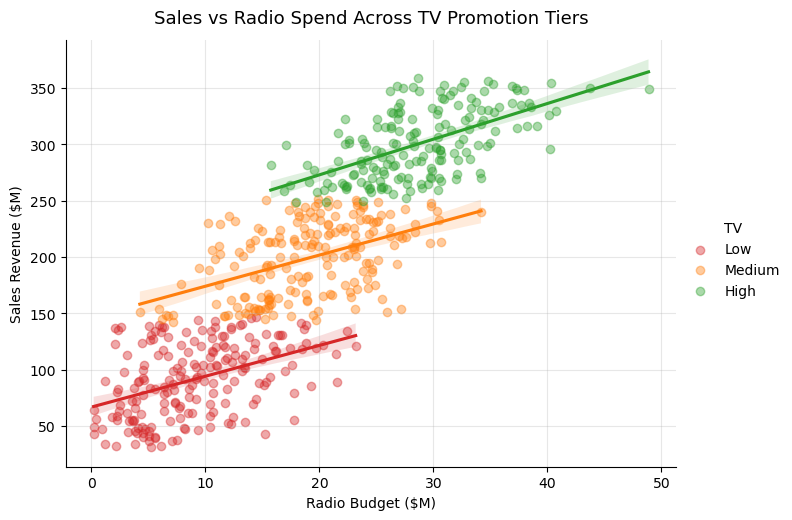

In [19]:
# Visualizing Regression Fit by TV Category (sns.lmplot)
g = sns.lmplot(
    data=data,
    x='Radio',
    y='Sales',
    hue='TV',
    hue_order=['Low', 'Medium', 'High'],
    palette={'Low': '#d62728', 'Medium': '#ff7f0e', 'High': '#2ca02c'},
    height=5,
    aspect=1.4,
    scatter_kws={'alpha': 0.4}
)
g.set_axis_labels("Radio Budget ($M)", "Sales Revenue ($M)")
plt.title("Sales vs Radio Spend Across TV Promotion Tiers", pad=12, fontsize=13)
plt.grid(True, alpha=0.3)
plt.show()


In [20]:
# ============================================================
# Out-of-Sample Validation (test set untouched until now)
# ============================================================
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Hold-out evaluation of the model fitted on the training data
y_pred = model.predict(test_df)
test_r2 = r2_score(test_df['Sales'], y_pred)
test_rmse = np.sqrt(mean_squared_error(test_df['Sales'], y_pred))
test_mae = mean_absolute_error(test_df['Sales'], y_pred)

# 5-fold CV on the training data only
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
train_reset = train_df.reset_index(drop=True)
for tr_idx, va_idx in cv.split(train_reset):
    m = ols(formula=ols_formula, data=train_reset.iloc[tr_idx]).fit()
    cv_scores.append(r2_score(train_reset.iloc[va_idx]['Sales'], m.predict(train_reset.iloc[va_idx])))
cv_scores = np.array(cv_scores)

print("="*60)
print("OUT-OF-SAMPLE GENERALIZATION METRICS")
print("="*60)
print(f"Train R²              : {model.rsquared:.4f}")
print(f"5-Fold CV R² (train)  : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Test R²               : {test_r2:.4f}")
print(f"Test RMSE ($M)        : {test_rmse:.4f}")
print(f"Test MAE ($M)         : {test_mae:.4f}")

OUT-OF-SAMPLE GENERALIZATION METRICS
Train R²              : 0.9008
5-Fold CV R² (train)  : 0.8995 ± 0.0087
Test R²               : 0.9152
Test RMSE ($M)        : 28.3261
Test MAE ($M)         : 24.0374


## Step 6: Conclusion

| Metric | Value |
|---|---|
| Selected model | `Sales ~ C(TV) + Radio` |
| Train R² / Adj. R² | 0.901 / 0.900 |
| 5-fold CV R² (train) | 0.900 ± 0.009 |
| **Hold-out Test R²** | **0.915** |
| Test RMSE / MAE | \$28.3M / \$24.0M |

**Data handling:** 3 rows with missing values were dropped (572 → 569), and there are no duplicate rows. The test set was split off **before** EDA and feature selection, so the test score is an unbiased estimate of out-of-sample performance.

**Assumptions:** linearity and independence hold, and there is no problematic multicollinearity (VIF < 5). Normality is mildly violated (light tails), and constant variance is borderline, so HC3 robust standard errors are used for inference.

**Business takeaway:** the TV budget level is the dominant driver of sales (High vs. Low ≈ \$152M difference), and Radio adds about \$2.89M of sales per \$1M spent within a TV tier. Because TV and Radio spend are confounded in this data, a controlled experiment would be needed to estimate the causal ROI of each channel.
